In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-08-20 17:23:30.749524: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import importlib
import DAE_DataGenerator

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_optDG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *
from dataset_utils import add_noise
import math


In [9]:
import models
importlib.reload(models)
from models import *
from loss import custom_sse_loss

weights_path = './SQ_DAE/model-63888c0a-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_845_MEMORYTEST-checkpoints'

model = CreateSQAE_SlimConv2DReg_fromweights((16,16,2), weights_path, FEBits = 2, OutBits = 2, n_filters=5, pool_size=3, 
                        conv_kernel_size=3, decoder_filters = 128)
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_sse_loss
)


Loading model from ./SQ_DAE/model-63888c0a-SQDAE_Conv2D_Categorical_2bit_80eN_Target_0_30_845_MEMORYTEST-checkpoints/weights.1084-t179620.4219-v173456.1875.hdf5
[array([2.3978953, 4.26268  , 6.5806394], dtype=float32), array([0.], dtype=float32)]
[array([5.856652 , 6.0416417, 4.9926186], dtype=float32), array([4.7312365], dtype=float32)]
latent space layer:  q_activation_30 (None, 4, 4, 5)
Model: "model_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 soft_quantizer_output (Soft  (None, 16, 16, 2)        4         
 QuantizeLayer)                                                  
                                                                 
 q_separable_conv2d_5 (QSepa  (None, 14, 14, 5)        33        
 rableConv2D)                                                 

In [3]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'train_contained/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_centeredIncidence_parquets", 'test_contained/')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3srCI_16x16_40eN_raw_slim')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3srCI_16x16_40eN_raw_slim')

# tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3sr_16x16_240eN_raw')
# tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3sr_16x16_240eN_raw')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_centeredIncidence_parquets/test_contained/


In [4]:
'''CHANGE THRESHOLDS AND TO_STANDARDIZE!!'''
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= False,
    select_contained = True,
    log_compression = False,
    noise = [0,40], #[mean, sigma]
    min_threshold = None,
    max_threshold = None,
    
    labels_list = ['x-midplane','y-midplane','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
print("--- Validation generator %s seconds ---" % (time.time() - start_time))

# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    log_compression = False,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= False,
    select_contained = True,
    labels_list = ['x-midplane','y-midplane','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,40],
    # threshold = -1,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:06<00:00,  3.04it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_40eN_raw_slim does not exist and cannot be removed.


Saving batches as TFRecords:   0%|          | 0/21 [00:00<?, ?it/s]2026-08-20 17:24:37.264824: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-20 17:24:37.312761: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-20 17:24:37.313226: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-08-20 17:24:37.314327: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To en

Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_40eN_raw_slim/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_40eN_raw_slim/metadata.json


--- Validation generator 16.533995866775513 seconds ---


Processing Files...: 100%|██████████| 80/80 [00:36<00:00,  2.18it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_40eN_raw_slim does not exist and cannot be removed.


Saving batches as TFRecords: 100%|██████████| 84/84 [00:35<00:00,  2.38it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_40eN_raw_slim/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_40eN_raw_slim/metadata.json


--- Training generator 73.27884769439697 seconds ---


In [11]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3srCI_16x16_80eN_raw_slim/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3srCI_16x16_80eN_raw_slim/metadata.json


In [8]:
print(training_generator[0][1])
# mask = [True, True, False, True]
# print(tf.boolean_mask(training_generator[0][1]))

tf.Tensor(
[[-0.8386478  -0.00404575  0.14942001]
 [-0.37780753 -0.26771614 -0.01604343]
 [ 0.15690857 -0.8120845  -0.34510264]
 ...
 [-0.5375583   0.11501282 -0.7759651 ]
 [-0.48657978 -0.8060973  -0.05436506]
 [-0.32236522  0.06692979 -0.14652216]], shape=(5000, 3), dtype=float32)


tf.Tensor([-0.20101489  0.67895174 -0.15027851], shape=(3,), dtype=float32)
max: 15980.1045
min: -2498.4048


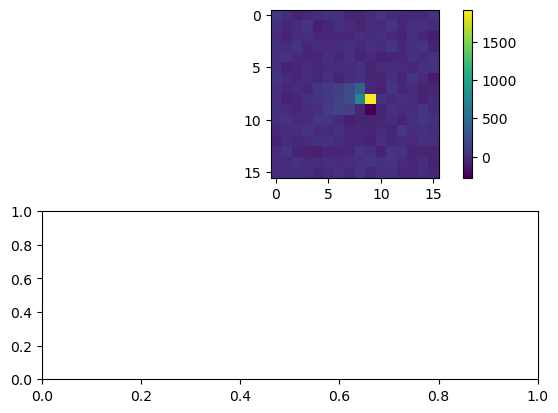

In [5]:
import matplotlib.pyplot as plt
from matplotlib import colors

n=90

cluster = validation_generator[0]
# print(np.max(cluster[0].numpy()))
print(cluster[1][n])
cluster=cluster[0][:,:,:,0]

print('max:', np.max(cluster.numpy()))
print('min:', np.min(cluster.numpy()))

fig,ax = plt.subplots(2,1)
h = ax[0].imshow(cluster[n])
fig.colorbar(h)

In [13]:
from datetime import datetime
tname = 'SQDAE_SQAutoEncoder_SlimConv2D_80e_2bit'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./SQ_DAE_regression/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.2f}-v{val_loss:.2f}.hdf5'
print(fingerprint)

70b2b21a


In [14]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 1000

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [15]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=4000,
        shuffle=False,
        verbose=1
    )

Epoch 1/4000
 1/84 [..............................] - ETA: 2:44 - loss: 6968.6240

2026-07-21 17:06:09.299331: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2026-07-21 17:06:09.406670: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


84/84 [==============================] - ETA: 0s - loss: 1312.7598
Epoch 1: val_loss improved from inf to 624.59576, saving model to ./SQ_DAE_regression/model-70b2b21a-SQDAE_SQAutoEncoder_SlimConv2D_80e_2bit-checkpoints/weights.01-t1312.76-v624.60.hdf5
84/84 [==============================] - 17s 184ms/step - loss: 1312.7598 - val_loss: 624.5958
Epoch 2/4000
83/84 [============================>.] - ETA: 0s - loss: 509.1036
Epoch 2: val_loss improved from 624.59576 to 413.41321, saving model to ./SQ_DAE_regression/model-70b2b21a-SQDAE_SQAutoEncoder_SlimConv2D_80e_2bit-checkpoints/weights.02-t507.92-v413.41.hdf5
84/84 [==============================] - 5s 60ms/step - loss: 507.9195 - val_loss: 413.4132
Epoch 3/4000
83/84 [============================>.] - ETA: 0s - loss: 356.9946
Epoch 3: val_loss improved from 413.41321 to 304.19571, saving model to ./SQ_DAE_regression/model-70b2b21a-SQDAE_SQAutoEncoder_SlimConv2D_80e_2bit-checkpoints/weights.03-t356.34-v304.20.hdf5
84/84 [=============

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



83/84 [============================>.] - ETA: 0s - loss: 60.9289
Epoch 2978: val_loss did not improve from 58.60802
84/84 [==============================] - 7s 86ms/step - loss: 60.8971 - val_loss: 60.1128
Epoch 2979/4000
83/84 [============================>.] - ETA: 0s - loss: 60.8010
Epoch 2979: val_loss did not improve from 58.60802
84/84 [==============================] - 7s 87ms/step - loss: 60.7735 - val_loss: 60.7475
Epoch 2980/4000
84/84 [==============================] - ETA: 0s - loss: 60.6888
Epoch 2980: val_loss did not improve from 58.60802
84/84 [==============================] - 7s 83ms/step - loss: 60.6888 - val_loss: 59.5102
Epoch 2981/4000
84/84 [==============================] - ETA: 0s - loss: 60.3477
Epoch 2981: val_loss did not improve from 58.60802
84/84 [==============================] - 7s 88ms/step - loss: 60.3477 - val_loss: 60.6644
Epoch 2982/4000
84/84 [==============================] - ETA: 0s - loss: 60.4063
Epoch 2982: val_loss did not improve from 58.60

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

